# 05 · Diagnóstico de atenuación y ensayos KAN (versión revisada: poda independiente y control de reajuste)

**Fuente:** ZIP `proyecto_final_analiticaDeDatos (2)(1).zip`, que contiene el script Python más reciente de los dos archivos remitidos. Este notebook reemplaza al 05 anterior. Ejecutar **Kernel → Restart & Run All** para evitar restos de variables del kernel antiguo.

**Objetivos, sin duplicar la ablación del notebook 02:** (1) diagnosticar reconstrucción FPCA, compresión de puntajes y picos con checkpoints cuando sean compatibles; (2) reentrenar una referencia controlada y variantes KAN con L1, L1+entropía, poda con reajuste y armónicos de la entrada satelital; (3) comparar por validación cruzada por estación.

**Alerta de fuentes:** el `Entrenamiento_red.py` reciente plantea entrenamiento 1981–1997 y prueba 1998–2003, pero el CSV incluido conserva entrenamiento 1981–1995, validación 1996–2000 y prueba 2001–2003, sin `grupo_vc`. **No se reetiquetan automáticamente fechas ni se unen particiones.** Los experimentos sobre el CSV disponible se consideran **exploratorios**, no resultados finales del nuevo protocolo. No se accede a las observaciones de prueba al ajustar los experimentos.

La entropía empleada mide la concentración de importancia de las aristas KAN; **no es pérdida de entropía cruzada para clasificación**. Los armónicos son proyecciones de la curva satelital de entrada, **no ondas añadidas a la precipitación predicha**. La variante armónica aumenta entradas y parámetros; se reporta como ensayo complementario y no como ablación oficial equitativa.

## 0. Preparación y validación de la exportación

In [1]:
from pathlib import Path
import os, sys, copy, random, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT/'funciones'/'Entrenamiento_red.py').exists():
    opciones = [p for p in ROOT.iterdir() if p.is_dir() and (p/'funciones'/'Entrenamiento_red.py').exists()]
    if len(opciones) == 1: ROOT = opciones[0]
if not (ROOT/'funciones'/'Entrenamiento_red.py').exists():
    raise FileNotFoundError('Ubica este notebook en la raíz de proyecto_final_analiticaDeDatos, junto al notebook 01.')
sys.path.insert(0,str(ROOT/'funciones'))
import Entrenamiento_red as er
SALIDA=ROOT/'Diagnostico_Atenuacion_KAN'; SALIDA.mkdir(exist_ok=True)
print('Proyecto:',ROOT,' | PyTorch:',torch.__version__,' | Escala:',er.ESCALA)
print('Se comprobarán explícitamente las etiquetas y años reales del CSV.')

# Compatible con el export CSV de este ZIP, que todavía no incluye grupo_vc.
# Se conserva exactamente la lógica de lectura y escala de cargar_datos_red() del proyecto.
def cargar_datos_red_compatible(carpeta,escala):
    carpeta=Path(carpeta)
    leer=lambda archivo:pd.read_csv(carpeta/archivo,dtype={'curva':str,'STATION_ID':str})
    meta=leer('metadatos_curvas.csv'); orden=meta.curva.to_numpy()
    coef=lambda archivo:leer(archivo).set_index('curva').loc[orden].to_numpy(dtype=np.float64)
    bs=pd.read_csv(carpeta/'base_satelite_malla_fina.csv')
    be=pd.read_csv(carpeta/'base_estaciones_malla_fina.csv')
    t=bs.t.to_numpy(dtype=np.float64)
    filas=[int(np.argmin(np.abs(t-k))) for k in range(1,73)]
    ps=bs.drop(columns='t').to_numpy(dtype=np.float64)
    pe=be.drop(columns='t').to_numpy(dtype=np.float64)
    return {'meta':meta,'particion':meta.particion.to_numpy(),
            'cov':meta[['altitud_completa','oni_promedio']].to_numpy(dtype=np.float64),
            'c_sat':er.coeficientes_en_escala(coef('coeficientes_satelite.csv'),ps,escala),
            'c_est':er.coeficientes_en_escala(coef('coeficientes_estaciones.csv'),pe,escala),
            'est_mm':np.maximum(coef('coeficientes_estaciones.csv')@pe.T,0),
            't':t,'filas_pentadas':filas,'phi_sat':ps,'phi_est':pe}

datos = cargar_datos_red_compatible(ROOT/'Curvas', escala=er.ESCALA)
meta = datos['meta'].copy()
print('Particiones:',pd.Series(datos['particion']).value_counts().to_dict())
assert set(np.unique(datos['particion'])) >= {'entrenamiento','prueba'}
if 'validacion' in set(datos['particion']):
    warnings.warn('La exportación conserva la partición ANTIGUA, no la especificada en Entrenamiento_red.py nuevo. No se reetiquetan años para evitar fuga.')
else:
    print('Exportación sin partición de validación fija: se usa CV por estación.')


Proyecto: c:\Users\maria\Downloads\proyecto_final_analiticaDeDatos  | PyTorch: 2.13.0+cpu  | Escala: raiz
Se comprobarán explícitamente las etiquetas y años reales del CSV.
Particiones: {'entrenamiento': 1450, 'validacion': 117, 'prueba': 67}


C:\Users\maria\AppData\Local\Temp\ipykernel_69804\124835204.py:47: UserWarning: La exportación conserva la partición ANTIGUA, no la especificada en Entrenamiento_red.py nuevo. No se reetiquetan años para evitar fuga.
  warnings.warn('La exportación conserva la partición ANTIGUA, no la especificada en Entrenamiento_red.py nuevo. No se reetiquetan años para evitar fuga.')


In [2]:
# Comprobar que los años almacenados corresponden a las etiquetas: no se reetiquetan.
assert 'year' in meta.columns or 'YEAR' in meta.columns or 'anio' in meta.columns or 'año' in meta.columns or 'curva' in meta.columns
col_ano=next((k for k in ('year','YEAR','anio','año') if k in meta.columns),None)
anos=(meta[col_ano].astype(int) if col_ano is not None else meta['curva'].astype(str).str.extract(r'(19\d{2}|20\d{2})$')[0].astype(int))
reporte=(pd.DataFrame({'anio':anos,'particion':datos['particion']}).groupby('particion').anio.agg(['min','max','count']))
display(reporte)
print('Años prueba en exportación:',sorted(anos[datos['particion']=='prueba'].unique().tolist()))


,min,max,count
particion,,,
entrenamiento,1981,1995,1450
prueba,2001,2003,67
validacion,1996,2000,117


Años prueba en exportación: [2001, 2002, 2003]


### Folds por estación

Si `grupo_vc` existe, se usan esos grupos siempre que sean válidos. Si falta, se generan **solo en el subconjunto realmente marcado como entrenamiento**, de modo reproducible por estación. Esta opción **no reproduce necesariamente** los folds del notebook 01 y debe declararse al interpretar resultados.

In [3]:
TRAIN = (datos['particion']=='entrenamiento')
TEST = (datos['particion']=='prueba')
FOLDS = 5
if 'grupo_vc' in meta.columns and meta.loc[TRAIN,'grupo_vc'].notna().all():
    grupos = meta['grupo_vc'].to_numpy()
    origen_grupos = 'Exportación R'
else:
    rng = np.random.default_rng(2026)
    estaciones = np.sort(meta.loc[TRAIN,'STATION_ID'].astype(str).unique())
    perm = estaciones.copy(); rng.shuffle(perm)
    asignacion = {str(s):(i % FOLDS)+1 for i,s in enumerate(perm)}
    grupos = np.array([asignacion.get(str(s), 0) for s in meta.STATION_ID])
    origen_grupos = 'Generados provisionalmente por estación (semilla 2026)'
    warnings.warn('No existe grupo_vc en metadatos: se generan folds reproducibles, que pueden diferir de los usados en 01–04.')
assert set(grupos[TRAIN]) == set(range(1,FOLDS+1))
assert all(meta.loc[TRAIN].assign(fold=grupos[TRAIN]).groupby('STATION_ID').fold.nunique()==1)
print('Origen:', origen_grupos)
display(pd.DataFrame({'fold':range(1,6),'n_curvas':[int(np.sum(TRAIN & (grupos==g))) for g in range(1,6)]}))
pd.DataFrame({'curva':meta.curva,'particion':datos['particion'],'grupo_vc_experimentos':grupos}).to_csv(SALIDA/'00_grupos_vc_usados.csv',index=False)
W_sat,R_sat = er.matrices_integracion(datos['t'],datos['phi_sat'])
W_est,R_est = er.matrices_integracion(datos['t'],datos['phi_est'])
CONFIG=pd.read_csv(ROOT/'Tablas'/'08_red_configuracion_elegida.csv').set_index('cabeza')
Q=int(CONFIG.loc['KAN','q']); M=int(CONFIG.loc['KAN','M']); LAM_RUG=float(CONFIG.loc['KAN','lambda'])
print('KAN base:',dict(q=Q,M=M,lambda_rugosidad=LAM_RUG,ocultas=er.OCULTAS_KAN,intervalos=er.INTERVALOS_KAN))
assert (Q,M)==(8,5), 'Revisar adaptaciones: la configuración elegida ha cambiado.'


Origen: Generados provisionalmente por estación (semilla 2026)


C:\Users\maria\AppData\Local\Temp\ipykernel_69804\1978770844.py:14: UserWarning: No existe grupo_vc en metadatos: se generan folds reproducibles, que pueden diferir de los usados en 01–04.
  warnings.warn('No existe grupo_vc en metadatos: se generan folds reproducibles, que pueden diferir de los usados en 01–04.')


,fold,n_curvas
0,1,308
1,2,291
2,3,280
3,4,280
4,5,291


KAN base: {'q': 8, 'M': 5, 'lambda_rugosidad': 100.0, 'ocultas': 4, 'intervalos': 12}


## 1. Diagnóstico con los checkpoints históricos, sin reentrenamiento

**Se ejecuta como un bloque autónomo**: crea `scores_real`, `scores_kan`, tablas y figuras en la misma celda. Así no falla por olvidar ejecutar una celda intermedia. Los checkpoints antiguos se usan exclusivamente como descripción histórica si pertenecen a estos datos; jamás como referencia de validación cruzada nueva.

Diagnóstico histórico disponible: True


,M,particion,varianza_entrenamiento_pct,RMSE_promedio_mm,ratio_desviacion_mediana,sesgo_pico_1_mm,sesgo_pico_2_mm
0,4,entrenamiento,92.142,3.953,0.988,-1.690,0.627
1,4,prueba,92.142,3.431,0.955,1.265,-0.864
2,4,validacion,92.142,5.109,1.071,-2.236,5.777
3,5,entrenamiento,96.423,2.508,1.022,-0.678,1.702
4,5,prueba,96.423,2.384,1.051,0.509,3.235
5,5,validacion,96.423,3.415,1.037,1.427,2.371
6,6,entrenamiento,100.000,1.172,1.028,1.277,1.984
7,6,prueba,100.000,1.343,1.040,1.413,2.469
8,6,validacion,100.000,1.088,1.026,1.461,1.508


Predicciones recuperadas: {1: (1634, 72), 2: (1634, 72), 3: (1634, 72)}
Chequeo de escala: medios de puntajes reales y KAN (entrenamiento), semilla 1:
   real     KAN
0   0.0  0.0224
1  -0.0  0.0354
2   0.0 -0.0230
3   0.0 -0.0206
4   0.0  0.0307


,semilla,particion,componente,std_real,std_KAN,ratio_std_pred_real,correlacion,error_medio
10,1,validacion,1,0.963,0.798,0.828,0.884,-0.066
11,1,validacion,2,1.040,0.273,0.263,0.200,-0.526
12,1,validacion,3,0.673,0.230,0.342,0.185,-0.105
13,1,validacion,4,1.020,0.237,0.233,0.281,-0.375
14,1,validacion,5,1.001,0.183,0.183,0.141,-0.436
25,2,validacion,1,0.963,0.950,0.987,0.877,0.125
26,2,validacion,2,1.040,0.378,0.363,0.505,-0.753
27,2,validacion,3,0.673,0.510,0.758,0.210,-0.044
28,2,validacion,4,1.020,0.408,0.400,0.158,-0.541
29,2,validacion,5,1.001,0.256,0.256,-0.087,-0.691


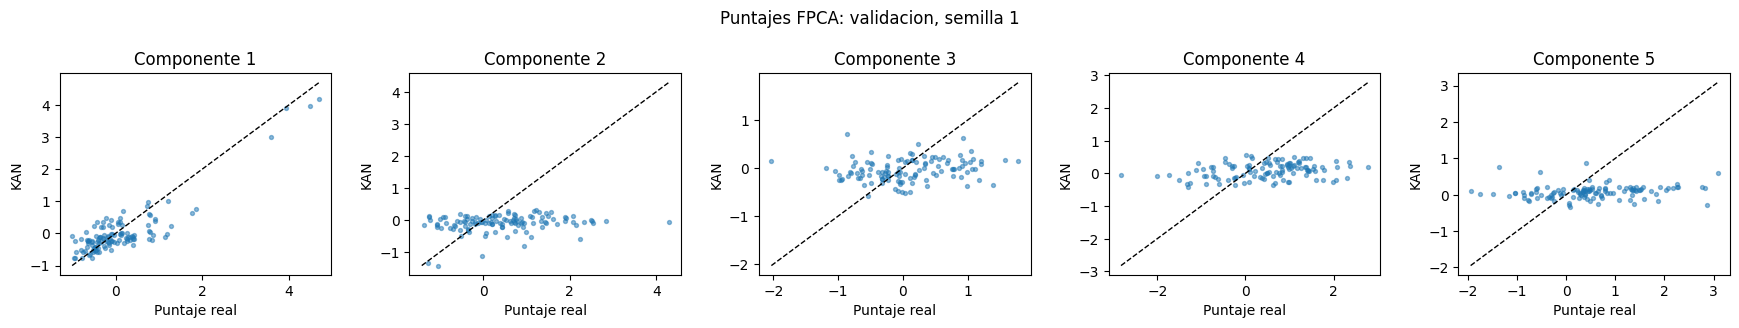

,particion,modelo,semilla,RMSE_mm,ratio_amplitud,sesgo_pico_1_mm,sesgo_pico_2_mm,mae_fecha_pico_1,mae_fecha_pico_2,sesgo_acumulado_pct
12,validacion,KAN,1,10.570,0.778,-11.136,-0.347,8.359,2.410,-4.282
13,validacion,KAN,2,11.326,0.917,-6.683,5.706,8.846,2.496,5.241
14,validacion,KAN,3,10.265,0.862,-6.293,3.464,8.308,2.487,2.636
15,validacion,Oraculo_FPCA,1,3.415,1.037,1.427,2.371,3.803,0.590,-0.928
16,validacion,Oraculo_FPCA,2,3.415,1.037,1.427,2.371,3.803,0.590,-0.928
17,validacion,Oraculo_FPCA,3,3.415,1.037,1.427,2.371,3.803,0.590,-0.928


semilla      RMSE_mm        ratio_amplitud       sesgo_pico_1_mm  \
                mean  std    mean    std           mean   std            mean   
modelo                                                                          
KAN              2.0  1.0  10.720  0.546          0.852  0.07          -8.037   
Oraculo_FPCA     2.0  1.0   3.415  0.000          1.037  0.00           1.427   

                   sesgo_pico_2_mm       mae_fecha_pico_1         \
               std            mean   std             mean    std   
modelo                                                             
KAN           2.69           2.941  3.06            8.504  0.297   
Oraculo_FPCA  0.00           2.371  0.00            3.803  0.000   

             mae_fecha_pico_2        sesgo_acumulado_pct         
                         mean    std                mean    std  
modelo                                                           
KAN                     2.464  0.047               1.198  4.922  
Oraculo_FPCA            0.590  0.000              -0.928  0.000

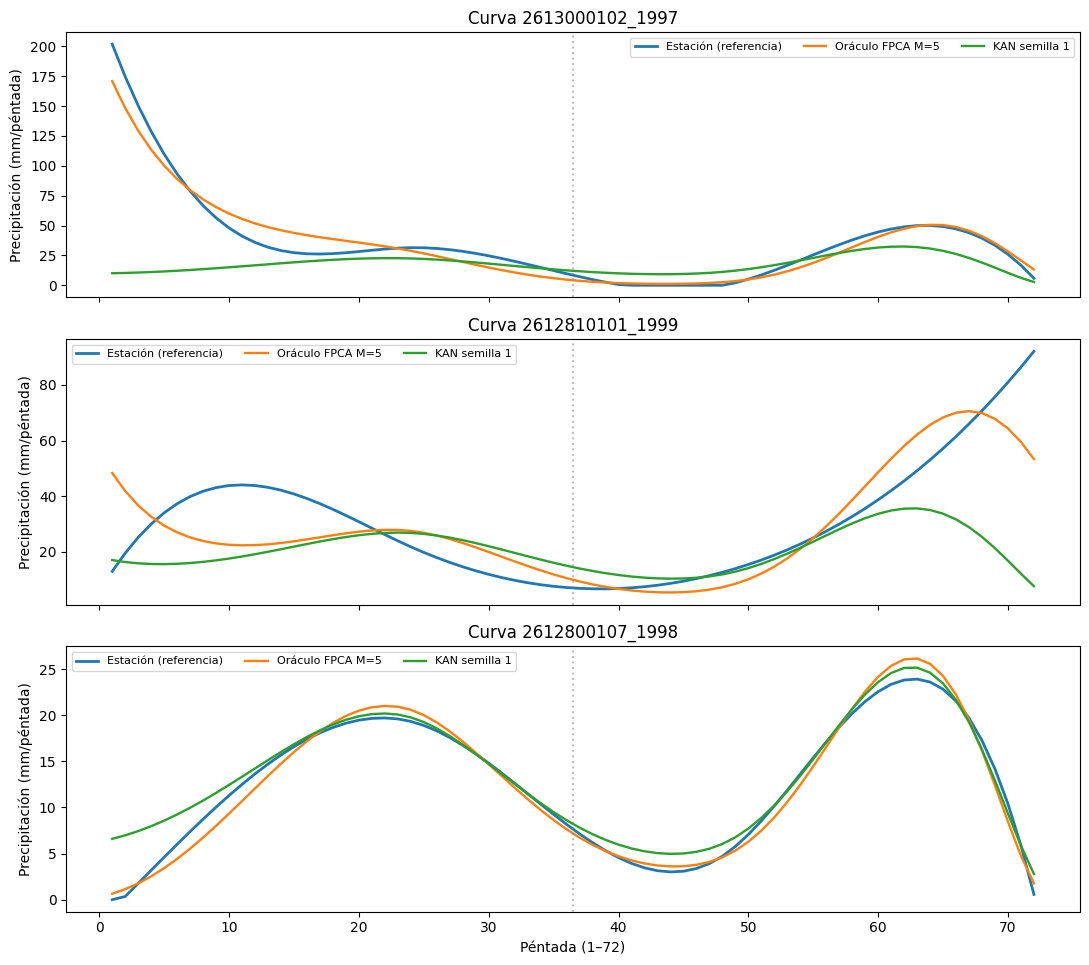

,semilla,particion,pct_valores_negativos_pre_recorte,pct_curvas_con_algun_negativo,valor_minimo_en_escala
0,1,entrenamiento,0.00,0.000,0.868
1,1,prueba,0.00,0.000,1.214
2,1,validacion,0.00,0.000,0.938
3,2,entrenamiento,0.00,0.000,0.158
4,2,prueba,0.00,0.000,0.986
5,2,validacion,0.00,0.000,0.171
6,3,entrenamiento,0.01,0.414,-0.790
7,3,prueba,0.00,0.000,0.771
8,3,validacion,0.00,0.000,1.133


In [4]:
# Identificar y cargar checkpoints SOLO si están completos y corresponden a la exportación.
SEMILLAS=(1,2,3)
ESCALA=er.ESCALA
idx_por_parte={p:np.flatnonzero(datos['particion']==p) for p in np.unique(datos['particion'])}
phi72=datos['phi_est'][datos['filas_pentadas']]
y_escala=datos['c_est']@phi72.T
Y_mm=datos['est_mm'][:,datos['filas_pentadas']]
fpca6=er.fit_fpca(y_escala[TRAIN],6)
PESOS=[ROOT/'Resultados_Modelos1'/f'red_KAN_semilla{s:04d}.pt' for s in SEMILLAS]
checks=[]
for peso in PESOS:
    if not peso.is_file():
        print('Checkpoint no encontrado:',peso.name)
        break
    checks.append(torch.load(peso,map_location='cpu',weights_only=False)) # únicamente archivos propios
historico_disponible=(len(checks)==3 and all(ch.get('q')==Q and ch.get('M')==M and ch.get('escala')==ESCALA for ch in checks))
print('Diagnóstico histórico disponible:',historico_disponible)

def inversa_a_mm(y_en_escala, escala):
    # Igual que reconstruir_mm: si el valor transformado es negativo, se recorta antes de invertir.
    fun_inversa = er.TRANSFORMACIONES[escala][1]
    return fun_inversa(np.maximum(np.asarray(y_en_escala),0.0))

def diagnostico_curvas(y_true, y_pred):
    # Filas=curvas, columnas=72 péntadas.
    a,b=np.asarray(y_true,dtype=float),np.asarray(y_pred,dtype=float)
    if a.shape!=b.shape or a.ndim!=2 or a.shape[1]!=72: raise ValueError('Se esperan matrices n x 72 del mismo tamaño.')
    media_a=a.mean(axis=1);media_b=b.mean(axis=1)
    sd_a=a.std(axis=1);sd_b=b.std(axis=1)
    rmse=np.sqrt(np.mean((b-a)**2,axis=1))
    # Definición operacional: dos semestres de 36 péntadas; NO son automáticamente
    # las dos temporadas climatológicas. Reportamos explícitamente la convención.
    max_a=np.column_stack([a[:,:36].max(axis=1),a[:,36:].max(axis=1)])
    max_b=np.column_stack([b[:,:36].max(axis=1),b[:,36:].max(axis=1)])
    arg_a=np.column_stack([a[:,:36].argmax(axis=1)+1,a[:,36:].argmax(axis=1)+37])
    arg_b=np.column_stack([b[:,:36].argmax(axis=1)+1,b[:,36:].argmax(axis=1)+37])
    return pd.DataFrame({
        'rmse_mm':rmse,
        'ratio_desviacion':np.divide(sd_b,sd_a,out=np.full_like(sd_a,np.nan),where=sd_a>1e-10),
        'bias_media_mm':media_b-media_a,
        'sesgo_acumulado_pct':np.divide(b.sum(axis=1)-a.sum(axis=1),a.sum(axis=1),out=np.full(len(a),np.nan),where=a.sum(axis=1)>1e-10)*100,
        'error_pico_1_mm':max_b[:,0]-max_a[:,0],
        'error_pico_2_mm':max_b[:,1]-max_a[:,1],
        'error_fecha_pico_1_pentadas':arg_b[:,0]-arg_a[:,0],
        'error_fecha_pico_2_pentadas':arg_b[:,1]-arg_a[:,1],
    })

recon_fpca = {}
filas_fpca=[]
for m in (4,5,6):
    B=fpca6['base'][:m]
    s=(y_escala-fpca6['media']) @ B.T
    y_hat=fpca6['media'] + s@B
    recon_fpca[m]=inversa_a_mm(y_hat,ESCALA)
    for particion,ids in idx_por_parte.items():
        diag=diagnostico_curvas(Y_mm[ids],recon_fpca[m][ids])
        filas_fpca.append({'M':m,'particion':particion,'varianza_entrenamiento_pct':100*fpca6['explicada'][:m].sum(),
                           'RMSE_promedio_mm':diag.rmse_mm.mean(), 'ratio_desviacion_mediana':diag.ratio_desviacion.median(),
                           'sesgo_pico_1_mm':diag.error_pico_1_mm.mean(), 'sesgo_pico_2_mm':diag.error_pico_2_mm.mean()})
tabla_fpca=pd.DataFrame(filas_fpca)
display(tabla_fpca.round(3))
tabla_fpca.to_csv(SALIDA/'01_techo_reconstruccion_FPCA.csv',index=False)



if historico_disponible:
    W_sat,R_sat=er.matrices_integracion(datos['t'],datos['phi_sat'])

    pred_kan={};scores_kan={};fpca_oraculo={};scores_real={}
    for ch in checks:
        seed=int(ch['semilla'])
        modelo=er.crear_modelo('KAN',W_sat,R_sat,int(ch['q']),int(ch['M']))
        modelo.load_state_dict(ch['estado'],strict=True)
        modelo.eval()
        cov_norm=(datos['cov']-ch['media_covariables'])/ch['desviacion_covariables']
        with torch.no_grad():
            puntuaciones=modelo(torch.as_tensor(datos['c_sat'],dtype=torch.float64),
                                torch.as_tensor(cov_norm,dtype=torch.float64)).numpy()
        # Exactamente la misma ruta que en el entrenamiento para pasar a la escala de la curva
        coef_hat=ch['media_coeficientes'][None,:]+puntuaciones@ch['base_coeficientes']
        curva_fina,_=er.reconstruir_mm(coef_hat,datos['phi_est'],ESCALA)
        pred_kan[seed]=curva_fina[:,datos['filas_pentadas']]
        scores_kan[seed]=puntuaciones
        s_verdaderos=np.linalg.lstsq(ch['base_fpca'].T,(y_escala-ch['media_fpca']).T,rcond=None)[0].T
        scores_real[seed]=s_verdaderos
        # Techo con la MISMA FPCA del checkpoint y LA MISMA proyección a coeficientes usada en la pérdida.
        coef_oraculo=ch['media_coeficientes'][None,:]+s_verdaderos@ch['base_coeficientes']
        curva_fina_oraculo,_=er.reconstruir_mm(coef_oraculo,datos['phi_est'],ESCALA)
        fpca_oraculo[seed]=curva_fina_oraculo[:,datos['filas_pentadas']]

    print('Predicciones recuperadas:',{k:v.shape for k,v in pred_kan.items()})
    print('Chequeo de escala: medios de puntajes reales y KAN (entrenamiento), semilla 1:')
    print(pd.DataFrame({'real':scores_real[1][idx_por_parte['entrenamiento']].mean(0),
                        'KAN':scores_kan[1][idx_por_parte['entrenamiento']].mean(0)}).round(4))


    filas_scores=[]
    for seed in SEMILLAS:
        for particion,ids in idx_por_parte.items():
            verdad=scores_real[seed][ids]
            pred=scores_kan[seed][ids]
            for j in range(M):
                std_true=np.std(verdad[:,j]);std_pred=np.std(pred[:,j])
                filas_scores.append({'semilla':seed,'particion':particion,'componente':j+1,
                                     'std_real':std_true,'std_KAN':std_pred,
                                     'ratio_std_pred_real':std_pred/std_true if std_true>1e-10 else np.nan,
                                     'correlacion':np.corrcoef(verdad[:,j],pred[:,j])[0,1] if std_true>1e-10 and std_pred>1e-10 else np.nan,
                                     'error_medio':(pred[:,j]-verdad[:,j]).mean()})
    tabla_scores=pd.DataFrame(filas_scores)
    particion_descriptiva = 'validacion' if 'validacion' in idx_por_parte else 'entrenamiento'
    display(tabla_scores.loc[tabla_scores.particion==particion_descriptiva].round(3))
    tabla_scores.to_csv(SALIDA/'02_diagnostico_puntajes.csv',index=False)

    fig,axes=plt.subplots(1,M,figsize=(3.5*M,3.3),sharex=False,sharey=False)
    ids=idx_por_parte[particion_descriptiva]
    for j,ax in enumerate(axes):
        ax.scatter(scores_real[1][ids,j],scores_kan[1][ids,j],s=8,alpha=.5)
        extremos=[min(scores_real[1][ids,j].min(),scores_kan[1][ids,j].min()),max(scores_real[1][ids,j].max(),scores_kan[1][ids,j].max())]
        ax.plot(extremos,extremos,'k--',lw=1)
        ax.set(xlabel='Puntaje real',ylabel='KAN',title=f'Componente {j+1}')
    fig.suptitle(f'Puntajes FPCA: {particion_descriptiva}, semilla 1')
    fig.tight_layout();fig.savefig(SALIDA/'02_puntajes_FPCA.png',dpi=160);plt.show()


    filas=[]
    for seed in SEMILLAS:
        for p,ids in idx_por_parte.items():
            for nombre, pred in [('Oraculo_FPCA',fpca_oraculo[seed]),('KAN',pred_kan[seed])]:
                d=diagnostico_curvas(Y_mm[ids],pred[ids])
                d.insert(0,'curva',datos['meta'].iloc[ids]['curva'].to_numpy())
                d.insert(0,'modelo',nombre);d.insert(0,'particion',p);d.insert(0,'semilla',seed)
                filas.append(d)
    detalle=pd.concat(filas,ignore_index=True)
    detalle.to_csv(SALIDA/'03_metricas_por_curva.csv',index=False)
    resumen=(detalle.groupby(['particion','modelo','semilla'],as_index=False)
             .agg(RMSE_mm=('rmse_mm','mean'),ratio_amplitud=('ratio_desviacion','median'),
                  sesgo_pico_1_mm=('error_pico_1_mm','mean'),sesgo_pico_2_mm=('error_pico_2_mm','mean'),
                  mae_fecha_pico_1=('error_fecha_pico_1_pentadas',lambda x:np.mean(np.abs(x))),
                  mae_fecha_pico_2=('error_fecha_pico_2_pentadas',lambda x:np.mean(np.abs(x))),
                  sesgo_acumulado_pct=('sesgo_acumulado_pct','mean')))
    resumen.to_csv(SALIDA/'04_resumen_por_semilla.csv',index=False)
    display(resumen.loc[resumen.particion==particion_descriptiva].round(3))
    # Media ± DE ENTRE 3 SEMILLAS. No son intervalos de confianza.
    promedios=resumen.groupby(['particion','modelo']).agg(['mean','std'])
    display(promedios.loc[particion_descriptiva].round(3))


    ids_va=idx_por_parte[particion_descriptiva]
    d_va=diagnostico_curvas(Y_mm[ids_va],pred_kan[1][ids_va])
    seleccion_local=[int(d_va.error_pico_1_mm.idxmin()),int(d_va.error_pico_2_mm.idxmin()),int(d_va.rmse_mm.idxmin())]
    seleccion=list(dict.fromkeys(ids_va[j] for j in seleccion_local))
    # Repetir visualmente ejemplos de hasta 3 curvas sin ocultar coincidencias.
    fig,axes=plt.subplots(len(seleccion),1,figsize=(11,3.25*len(seleccion)),sharex=True)
    axes=np.atleast_1d(axes)
    for ax,i in zip(axes,seleccion):
        ax.plot(np.arange(1,73),Y_mm[i],label='Estación (referencia)',lw=2)
        ax.plot(np.arange(1,73),fpca_oraculo[1][i],label='Oráculo FPCA M=5',lw=1.7)
        ax.plot(np.arange(1,73),pred_kan[1][i],label='KAN semilla 1',lw=1.7)
        ax.axvline(36.5,ls=':',color='gray',alpha=.5)
        ax.set(ylabel='Precipitación (mm/péntada)',title=f"Curva {datos['meta'].iloc[i]['curva']}")
        ax.legend(ncol=3,fontsize=8)
    axes[-1].set_xlabel('Péntada (1–72)')
    fig.tight_layout();fig.savefig(SALIDA/'05_curvas_reales_FPCA_KAN.png',dpi=160);plt.show()


    filas_recortes=[]
    for ch in checks:
        seed=int(ch['semilla'])
        coef_hat=ch['media_coeficientes'][None,:]+scores_kan[seed]@ch['base_coeficientes']
        crudo=coef_hat@datos['phi_est'].T
        for p,ids in idx_por_parte.items():
            cr=crudo[ids][:,datos['filas_pentadas']]
            filas_recortes.append({'semilla':seed,'particion':p,'pct_valores_negativos_pre_recorte':100*np.mean(cr<0),
                                   'pct_curvas_con_algun_negativo':100*np.mean((cr<0).any(axis=1)),
                                   'valor_minimo_en_escala':float(cr.min())})
    tabla_recortes=pd.DataFrame(filas_recortes)
    display(tabla_recortes.round(3))
    tabla_recortes.to_csv(SALIDA/'06_recortes_transformacion.csv',index=False)

else:
    print("Diagnóstico FPCA calculado; checkpoints no compatibles. Se omiten las comparaciones históricas sin impedir los experimentos nuevos.")


## 2. Nuevos experimentos: KAN, regularización y poda aislada

La ablación de arquitectura ya existe en el notebook 02 y no se repite. Para aislar los efectos, distinguimos:

- **original**: KAN sin L1, entropía ni poda, con una fase de entrenamiento.
- **l1**: KAN con L1, una fase.
- **l1_entropia**: KAN con L1 y entropía, una fase.
- **control_reajuste**: KAN **sin L1 ni entropía**, con entrenamiento inicial y un segundo ajuste **sin podar**.
- **poda**: KAN **sin L1 ni entropía**, con el mismo entrenamiento inicial, luego poda del 20 % de aristas por capa y segundo ajuste.
- **armonicos**: entradas sinusoidales del satélite, sin otras penalizaciones.

La comparación primaria que aísla el **efecto de la poda** es `poda` frente a `control_reajuste`, no `poda` frente a `l1_entropia`. Se emplea la misma semilla, fold, duración y paciencia para las dos fases. El control no poda aristas. La selección del mejor estado se hace por validación dentro del fold, sin usar el conjunto de prueba.

**Nota:** el tratamiento podado no equivale a eliminar neuronas completas: anula aristas de baja importancia y recalibra las conexiones activas.

In [5]:
class CapaKANPodable(er.CapaKAN):
    def __init__(self, entradas, salidas, intervalos=er.INTERVALOS_KAN):
        super().__init__(entradas, salidas, intervalos)
        self.register_buffer('mascara_aristas',torch.ones(salidas,entradas,dtype=torch.float64))

    def contribuciones(self,x):
        norm=(x-self.centro)/self.escala
        base=nn.functional.silu(norm).unsqueeze(1)*self.peso_base.unsqueeze(0)
        cs=self.peso_spline.unsqueeze(-1)*self.coeficientes
        spl=torch.einsum('big,oig->boi',self.bases(norm),cs)
        return base+spl

    def forward(self,x):
        return (self.contribuciones(x)*self.mascara_aristas.unsqueeze(0)).sum(dim=2)

    def importancia(self,x):
        return (self.contribuciones(x)*self.mascara_aristas.unsqueeze(0)).abs().mean(dim=0)

class KANExperimental(nn.Module):
    def __init__(self,armonicos=False):
        super().__init__()
        self.codificador=er.CodificadorFuncional(W_sat,Q,R_sat)
        self.armonicos=armonicos
        extra=4 if armonicos else 0
        self.cabeza=nn.ModuleList([CapaKANPodable(Q+2+extra,er.OCULTAS_KAN),
                                    CapaKANPodable(er.OCULTAS_KAN,M)])
        # Proyecciones funcionales normalizadas por duración; modelo sólo mira el satélite.
        t=np.asarray(datos['t'],dtype=float)
        s=(t-t[0])/(t[-1]-t[0])
        armonicas=np.stack([np.sin(2*np.pi*s),np.cos(2*np.pi*s),np.sin(4*np.pi*s),np.cos(4*np.pi*s)],axis=1)
        integr=np.array([np.trapezoid(datos['phi_sat']*armonicas[:,j,None],t,axis=0) / (t[-1]-t[0]) for j in range(4)]).T
        self.register_buffer('pesos_armonicos',torch.as_tensor(integr,dtype=torch.float64))
        self.register_buffer('media_arm',torch.zeros(4,dtype=torch.float64))
        self.register_buffer('std_arm',torch.ones(4,dtype=torch.float64))

    def entradas(self,c,cov):
        z=self.codificador(c,cov)
        if self.armonicos:
            a=(c@self.pesos_armonicos-self.media_arm)/self.std_arm
            z=torch.cat([z,a],dim=1)
        return z

    def forward(self,c,cov):
        h=self.entradas(c,cov)
        for capa in self.cabeza:h=capa(h)
        return h

    @torch.no_grad()
    def calibrar(self,c,cov):
        if self.armonicos:
            a=c@self.pesos_armonicos
            self.media_arm.copy_(a.mean(0))
            self.std_arm.copy_(a.std(0,unbiased=False).clamp_min(1e-8))
        h=self.entradas(c,cov)
        for capa in self.cabeza:
            capa.calibrar(h)
            h=capa(h)

    def penalizaciones(self,c,cov):
        h=self.entradas(c,cov)
        l1=h.new_zeros(()); ent=h.new_zeros(())
        for capa in self.cabeza:
            imp=capa.importancia(h)
            p=imp/(imp.sum()+1e-12)
            l1=l1+imp.sum()
            ent=ent-(p*torch.log(p.clamp_min(1e-12))).sum()
            h=capa(h)
        return l1,ent

    @torch.no_grad()
    def podar(self,c,cov,fraccion=0.20):
        h=self.entradas(c,cov)
        eliminadas=[]
        for capa in self.cabeza:
            importancia=capa.importancia(h).flatten()
            n=int(np.floor(fraccion*importancia.numel()))
            if n>0:
                orden=torch.argsort(importancia)
                nueva=torch.ones_like(importancia)
                nueva[orden[:n]]=0
                capa.mascara_aristas.copy_(nueva.view_as(capa.mascara_aristas))
            eliminadas.append(int((capa.mascara_aristas==0).sum()))
            h=capa(h)
        return eliminadas

# Verificación: sin máscara y sin armónicos, forward reproduce la CapaKAN original.
torch.manual_seed(2026)
x=torch.randn(7,Q+2,dtype=torch.float64)
a=er.CapaKAN(Q+2,4); b=CapaKANPodable(Q+2,4)
b.load_state_dict(a.state_dict(),strict=False)
assert torch.allclose(a(x),b(x),atol=1e-10), 'Fallo equivalencia en implementación de aristas'
print('Prueba de equivalencia de aristas: OK')


Prueba de equivalencia de aristas: OK


## 3. Funciones de entrenamiento controlado

Todos los folds recalculan FPCA y normalización únicamente con las estaciones de ajuste. Las variantes `poda` y `control_reajuste` realizan dos fases de entrenamiento de **igual presupuesto**; se seleccionan aristas por su importancia en entrenamiento y se reajustan los parámetros restantes. Los otros tratamientos mantienen una fase, por lo que su comparación con `poda` es exploratoria; para el efecto causal de quitar conexiones se compara solo con `control_reajuste`.


In [6]:
# Esta celda DEFINE el experimento; no entrena hasta ejecutar la sección 5.
SEMILLAS=(1,2,3)
EPOCAS=int(er.EPOCAS_MAXIMAS)  # presupuesto de entrenamiento del proyecto
PACIENCIA=int(er.PACIENCIA)
LR=float(er.TASA_APRENDIZAJE)
FRACCION_PODA=0.20
# Niveles moderados iniciales: no se presentan como óptimos; ajustar únicamente con CV.
FRAC_L1=0.01
FRAC_ENT=0.005

T=lambda a:torch.as_tensor(a,dtype=torch.float64)

def construir_modelo(filas_ajuste,semilla,armonicos=False):
    er.establecer_semilla(semilla)
    normal=er.NormalizadorCovariables().ajustar(datos['cov'],filas_ajuste)
    cov_norm=normal.transformar(datos['cov'])
    fpca,mu,psi,_=er.preparar_fpca(datos,M,filas_ajuste)
    modelo=KANExperimental(armonicos=armonicos)
    c=T(datos['c_sat'][filas_ajuste]); h=T(cov_norm[filas_ajuste])
    modelo.calibrar(c,h)
    loss=er.PerdidaFuncional(W_est,mu,psi,LAM_RUG)
    return modelo,loss,cov_norm

def entrenar_variante(filas_ajuste,filas_val,semilla,tratamiento,epocas=EPOCAS,patiencia=PACIENCIA):
    # Tratamientos: original, l1, l1_entropia, control_reajuste, poda, armonicos.
    assert tratamiento in ('original','l1','l1_entropia','control_reajuste','poda','armonicos')
    assert np.all(filas_ajuste<=TRAIN) and np.all(filas_val<=TRAIN)
    assert not np.any(filas_ajuste & filas_val)
    modelo,loss,cov_norm=construir_modelo(filas_ajuste,semilla,armonicos=(tratamiento=='armonicos'))
    c_tr,h_tr,y_tr=T(datos['c_sat'][filas_ajuste]),T(cov_norm[filas_ajuste]),T(datos['c_est'][filas_ajuste])
    c_va,h_va,y_va=T(datos['c_sat'][filas_val]),T(cov_norm[filas_val]),T(datos['c_est'][filas_val])
    utiliza_l1=tratamiento in ('l1','l1_entropia')
    utiliza_ent=tratamiento == 'l1_entropia'
    # Coeficientes fijados sin consultar validación.
    with torch.no_grad():
        error0=float(loss.error_l2(modelo(c_tr,h_tr),y_tr).item())
        l10,ent0=modelo.penalizaciones(c_tr,h_tr)
        coef_l1=(FRAC_L1*error0/max(float(l10),1e-12)) if utiliza_l1 else 0.0
        coef_ent=(FRAC_ENT*error0/max(float(ent0),1e-12)) if utiliza_ent else 0.0

    def fase(num_epocas,nombre_fase="ajuste"):
        opt=torch.optim.AdamW(modelo.parameters(),lr=LR,weight_decay=0)
        mejor=np.inf; estado=None; mejor_epoca=0; malas=0; historial=[]
        for ep in range(1,num_epocas+1):
            modelo.train(); opt.zero_grad(set_to_none=True)
            pred=modelo(c_tr,h_tr)
            obj=loss(pred,y_tr,modelo.codificador)
            if utiliza_l1 or utiliza_ent:
                penal1,penalH=modelo.penalizaciones(c_tr,h_tr)
                obj=obj+coef_l1*penal1+coef_ent*penalH
            obj.backward()
            # Mantener cero los gradientes de aristas podadas, además de las máscaras del forward.
            for capa in modelo.cabeza:
                if capa.peso_base.grad is not None:
                    capa.peso_base.grad.mul_(capa.mascara_aristas)
                    capa.peso_spline.grad.mul_(capa.mascara_aristas)
                    capa.coeficientes.grad.mul_(capa.mascara_aristas.unsqueeze(-1))
            opt.step(); modelo.eval()
            with torch.no_grad():
                val=float(loss.error_l2(modelo(c_va,h_va),y_va))
            historial.append((ep,float(obj.detach()),val,nombre_fase))
            if val<mejor-1e-10:
                mejor=val; estado=copy.deepcopy(modelo.state_dict()); mejor_epoca=ep; malas=0
            else:
                malas+=1
                if malas>=patiencia:break
        modelo.load_state_dict(estado)
        return mejor,mejor_epoca,historial

    mejor,mejor_epoca,hist=fase(epocas,nombre_fase="ajuste")
    borradas=[0 for _ in modelo.cabeza]
    epocas_reajuste= max(50,epocas//3)
    if tratamiento in ('poda','control_reajuste'):
        if tratamiento=='poda':
            borradas=modelo.podar(c_tr,h_tr,FRACCION_PODA)
        # Comparación pareada: mismo presupuesto de reajuste para podada y sin podar.
        # Ambas arrancan del mejor checkpoint de la primera fase.
        mejor,mejor_epoca,hist2=fase(epocas_reajuste,nombre_fase=('reajuste_podado' if tratamiento=='poda' else 'reajuste_control'))
        hist+=hist2
    with torch.no_grad():
        puntajes=modelo(c_va,h_va)
        coefs=loss.coeficientes(puntajes).detach().cpu().numpy()
        pred_mm,_=er.reconstruir_mm(coefs,datos['phi_est'],er.ESCALA)
    return {'modelo':modelo,'loss':loss,'cov_norm':cov_norm,'pred_mm':pred_mm,'mejor_L2':mejor,
            'mejor_epoca':mejor_epoca,'historia':hist,'podadas':borradas,'coef_l1':coef_l1,'coef_ent':coef_ent}


## 4. Ejecutar los experimentos por folds

**Se mantienen los 5 folds ya definidos por estación; no se agregan folds nuevos.** Cinco son los especificados en el proyecto. Para ver estabilidad sin el costo de 3 semillas se permite una exploración de los cinco folds con una semilla y pocas épocas. Eso **no** permite concluir que la modificación mejora de forma definitiva.

- `MODO_PRUEBA = True`: entrenamiento corto; con `FOLDS_EXPLORATORIOS=(1,2,3,4,5)` se ensayan los cinco folds, una semilla. Para comprobación técnica rápida se puede poner `(1,)`.
- `MODO_PRUEBA = False`: 5 folds, 3 semillas, presupuesto original; usar únicamente después de alinear los CSV y la partición definitiva.

**Importante:** si `grupo_vc` no existe en la exportación, el notebook asigna folds provisionales por estación. Son reproducibles, pero no necesariamente idénticos a los de los notebooks 01–04. Para comparación oficial debe exportarse `grupo_vc` desde R.


In [7]:
MODO_PRUEBA = True  # Cambiar a False para resultados finales con el presupuesto del proyecto.
TRATAMIENTOS=('original','l1','l1_entropia','control_reajuste','poda','armonicos')
EPOCAS_EJECUCION=30 if MODO_PRUEBA else EPOCAS
PACIENCIA_EJECUCION=15 if MODO_PRUEBA else PACIENCIA

# Explorar estabilidad con los 5 folds existentes, sin crear más folds.
# Para una ejecución mínima puede cambiarse a (1,).
FOLDS_EXPLORATORIOS=(1,2,3,4,5)
FOLDS_RUN=FOLDS_EXPLORATORIOS if MODO_PRUEBA else tuple(range(1,FOLDS+1))
SEEDS_RUN=(1,) if MODO_PRUEBA else SEMILLAS
assert set(FOLDS_RUN).issubset(set(range(1,FOLDS+1)))
print(f'Ensayos: {len(FOLDS_RUN)} folds × {len(SEEDS_RUN)} semillas × {len(TRATAMIENTOS)} variantes = {len(FOLDS_RUN)*len(SEEDS_RUN)*len(TRATAMIENTOS)} ajustes')

filas_cv=[]; curvas_cv=[]; historiales=[]
for fold in FOLDS_RUN:
    ajuste=TRAIN & (grupos!=fold)
    validacion=TRAIN & (grupos==fold)
    assert int(ajuste.sum())>0 and int(validacion.sum())>0
    for seed in SEEDS_RUN:
        for tratamiento in TRATAMIENTOS:
            resultado=entrenar_variante(ajuste,validacion,seed,tratamiento,
                                        epocas=EPOCAS_EJECUCION,patiencia=PACIENCIA_EJECUCION)
            obs=datos['est_mm'][validacion][:,datos['filas_pentadas']]
            pred=resultado['pred_mm'][:,datos['filas_pentadas']]
            rmse=float(np.sqrt(np.mean((pred-obs)**2)))
            ratio=float(np.median(np.std(pred,axis=1)/(np.std(obs,axis=1)+1e-12)))
            fila={'fold':fold,'semilla':seed,'variante':tratamiento,'modo_prueba':MODO_PRUEBA,
                  'L2_validacion':resultado['mejor_L2'],'RMSE_mm':rmse,'ratio_amplitud':ratio,
                  'mejor_epoca':resultado['mejor_epoca'],'aristas_podadas':sum(resultado['podadas']),
                  'lambda_L1_efectiva':resultado['coef_l1'],'lambda_entropia_efectiva':resultado['coef_ent'],
                  'n_validacion':int(validacion.sum()),
                  'epocas_primera_fase':int(EPOCAS_EJECUCION),
                  'epocas_max_reajuste':int(max(50,EPOCAS_EJECUCION//3)) if tratamiento in ('poda','control_reajuste') else 0}
            filas_cv.append(fila)
            for k,idx in enumerate(np.flatnonzero(validacion)):
                curvas_cv.append({'curva':meta.iloc[idx].curva,'fold':fold,'semilla':seed,'variante':tratamiento,
                                  'RMSE_mm_curva':float(np.sqrt(np.mean((pred[k]-obs[k])**2))),
                                  'ratio_amplitud_curva':float(np.std(pred[k])/(np.std(obs[k])+1e-12))})
            for ep,tr_l,va_l,fase in resultado['historia']:
                historiales.append({'fold':fold,'semilla':seed,'variante':tratamiento,'epoca':ep,
                                    'fase':fase,'perdida_entrenamiento':tr_l,'L2_validacion':va_l})
            print(f'fold {fold} · seed {seed} · {tratamiento}: RMSE={rmse:.3f}, amplitud={ratio:.3f}',flush=True)
            pd.DataFrame(filas_cv).to_csv(SALIDA/('10_cv_prueba_rapida.csv' if MODO_PRUEBA else '10_cv_final.csv'),index=False)

resumen_cv=pd.DataFrame(filas_cv)
display(resumen_cv.round(4))
pd.DataFrame(curvas_cv).to_csv(SALIDA/('11_curvas_cv_prueba_rapida.csv' if MODO_PRUEBA else '11_curvas_cv_final.csv'),index=False)
pd.DataFrame(historiales).to_csv(SALIDA/('12_historiales_prueba_rapida.csv' if MODO_PRUEBA else '12_historiales_final.csv'),index=False)


Ensayos: 5 folds × 1 semillas × 6 variantes = 30 ajustes
fold 1 · seed 1 · original: RMSE=10.520, amplitud=0.778
fold 1 · seed 1 · l1: RMSE=10.547, amplitud=0.773
fold 1 · seed 1 · l1_entropia: RMSE=10.549, amplitud=0.771
fold 1 · seed 1 · control_reajuste: RMSE=10.142, amplitud=0.826
fold 1 · seed 1 · poda: RMSE=9.909, amplitud=0.843
fold 1 · seed 1 · armonicos: RMSE=10.358, amplitud=0.772
fold 2 · seed 1 · original: RMSE=21.219, amplitud=0.801
fold 2 · seed 1 · l1: RMSE=21.378, amplitud=0.807
fold 2 · seed 1 · l1_entropia: RMSE=21.362, amplitud=0.807
fold 2 · seed 1 · control_reajuste: RMSE=20.260, amplitud=0.749
fold 2 · seed 1 · poda: RMSE=19.693, amplitud=0.824
fold 2 · seed 1 · armonicos: RMSE=26.941, amplitud=0.848
fold 3 · seed 1 · original: RMSE=11.423, amplitud=0.893
fold 3 · seed 1 · l1: RMSE=11.309, amplitud=0.893
fold 3 · seed 1 · l1_entropia: RMSE=11.309, amplitud=0.894
fold 3 · seed 1 · control_reajuste: RMSE=10.884, amplitud=0.889
fold 3 · seed 1 · poda: RMSE=10.778, am

,fold,semilla,variante,modo_prueba,L2_validacion,RMSE_mm,ratio_amplitud,mejor_epoca,aristas_podadas,lambda_L1_efectiva,lambda_entropia_efectiva,n_validacion,epocas_primera_fase,epocas_max_reajuste
0,1,1,original,True,90.1604,10.5199,0.7777,30,0,0.0000,0.0000,308,30,0
1,1,1,l1,True,90.8451,10.5472,0.7732,30,0,0.4796,0.0000,308,30,0
2,1,1,l1_entropia,True,90.8287,10.5489,0.7714,30,0,0.4796,0.1642,308,30,0
3,1,1,control_reajuste,True,80.8457,10.1419,0.8255,28,0,0.0000,0.0000,308,30,50
4,1,1,poda,True,76.9382,9.9093,0.8429,42,12,0.0000,0.0000,308,30,50
5,1,1,armonicos,True,86.3406,10.3577,0.7717,30,0,0.0000,0.0000,308,30,0
6,2,1,original,True,152.2354,21.2189,0.8005,29,0,0.0000,0.0000,291,30,0
7,2,1,l1,True,153.2974,21.3784,0.8069,29,0,0.3205,0.0000,291,30,0
8,2,1,l1_entropia,True,153.1508,21.3621,0.8065,29,0,0.3205,0.0991,291,30,0
9,2,1,control_reajuste,True,140.1797,20.2600,0.7487,22,0,0.0000,0.0000,291,30,50


## 5. Resumen y comparación pareada **poda vs. control con reajuste**

Los resúmenes generales son descriptivos. Para aislar el efecto de eliminar aristas, calculamos por fold y semilla las diferencias `poda − control_reajuste` en RMSE, pérdida L² y relación de amplitud. Valores negativos de diferencia de RMSE favorecen la poda; para amplitud interesa acercarse a 1, no solo que aumente. En modo de prueba, las diferencias siguen siendo **exploratorias**.


,variante,RMSE_media,RMSE_std,amplitud_media,L2_media,n_ajustes
0,armonicos,14.3026,7.2426,0.8525,114.6080,5
1,control_reajuste,12.7403,4.3867,0.8774,92.5482,5
2,l1,13.3580,4.6682,0.8628,104.6153,5
3,l1_entropia,13.3418,4.6732,0.8578,104.6163,5
4,original,13.3337,4.5961,0.8654,104.5097,5
5,poda,12.5766,4.1875,0.8979,91.7268,5


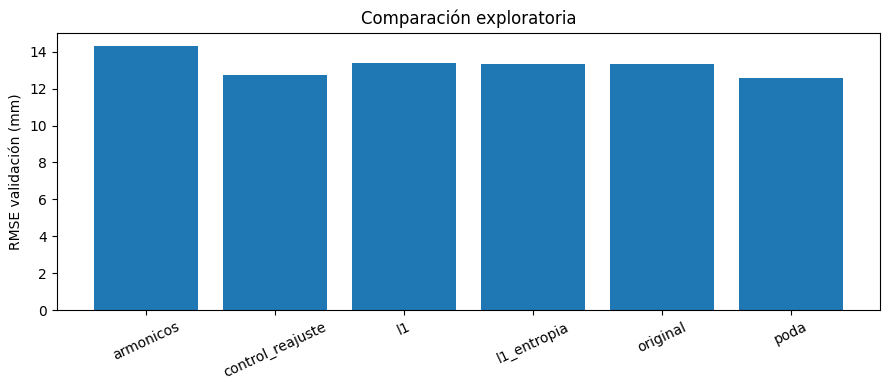

,,RMSE_mm_poda,L2_validacion_poda,ratio_amplitud_poda,RMSE_mm_control,L2_validacion_control,ratio_amplitud_control,delta_RMSE_poda_menos_control,delta_L2_poda_menos_control,mejora_error_amplitud
fold,semilla,,,,,,,,,
1,1,9.9093,76.9382,0.8429,10.1419,80.8457,0.8255,-0.2327,-3.9075,0.0174
2,1,19.6935,137.5482,0.8244,20.2600,140.1797,0.7487,-0.5665,-2.6315,0.0757
3,1,10.7785,91.9489,0.9130,10.8840,91.8412,0.8886,-0.1056,0.1078,0.0244
4,1,12.9281,80.8514,0.9366,12.8706,78.5712,0.9154,0.0575,2.2801,0.0212
5,1,9.5736,71.3474,0.9727,9.5447,71.3033,1.0090,0.0289,0.0441,-0.0183


ATENCIÓN: entrenamiento reducido / 5 folds / 1 semilla(s). NO son resultados definitivos.
La poda y su control tienen la misma cantidad máxima de épocas en ambas fases.


In [8]:
assert len(resumen_cv)>0
resumen = resumen_cv.groupby('variante',as_index=False).agg(RMSE_media=('RMSE_mm','mean'),
                                  RMSE_std=('RMSE_mm','std'),amplitud_media=('ratio_amplitud','mean'),
                                  L2_media=('L2_validacion','mean'),n_ajustes=('RMSE_mm','size'))
display(resumen.round(4))
resumen.to_csv(SALIDA/('13_resumen_prueba_rapida.csv' if MODO_PRUEBA else '13_resumen_cv_final.csv'),index=False)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(resumen.variante,resumen.RMSE_media)
ax.set_ylabel('RMSE validación (mm)');ax.set_title('Comparación exploratoria' if MODO_PRUEBA else 'CV por estación: promedio folds y semillas')
ax.tick_params(axis='x',rotation=25);fig.tight_layout()
fig.savefig(SALIDA/('13_RMSE_prueba_rapida.png' if MODO_PRUEBA else '13_RMSE_cv.png'),dpi=160)
plt.show()
# Pareo dentro de los mismos folds y semillas: poda frente al reajuste sin poda.
p= resumen_cv[resumen_cv.variante=='poda'].set_index(['fold','semilla'])
c= resumen_cv[resumen_cv.variante=='control_reajuste'].set_index(['fold','semilla'])
pares=p[['RMSE_mm','L2_validacion','ratio_amplitud']].join(
    c[['RMSE_mm','L2_validacion','ratio_amplitud']],lsuffix='_poda',rsuffix='_control',how='inner')
pares['delta_RMSE_poda_menos_control']=pares['RMSE_mm_poda']-pares['RMSE_mm_control']
pares['delta_L2_poda_menos_control']=pares['L2_validacion_poda']-pares['L2_validacion_control']
pares['mejora_error_amplitud']=abs(pares['ratio_amplitud_control']-1)-abs(pares['ratio_amplitud_poda']-1)
display(pares.round(4))
pares.to_csv(SALIDA/('14_poda_vs_control_prueba.csv' if MODO_PRUEBA else '14_poda_vs_control_final.csv'))
if MODO_PRUEBA:
    print(f'ATENCIÓN: entrenamiento reducido / {len(FOLDS_RUN)} folds / {len(SEEDS_RUN)} semilla(s). NO son resultados definitivos.')
    print('La poda y su control tienen la misma cantidad máxima de épocas en ambas fases.')



## 6. Interpretación y límites

- **La poda ahora es independiente de L1 y entropía.** Entrena una KAN normal, elimina las aristas de menor importancia (calculada **solo con entrenamiento**) y reajusta las conexiones activas.
- **Control de reajuste:** misma arquitectura, semilla, fold, primera fase y segunda fase, pero sin eliminar aristas. Solo la comparación `poda - control_reajuste` permite atribuir una diferencia a quitar aristas con mayor fundamento.
- **L1:** comprueba el efecto de penalizar la magnitud de las contribuciones de aristas, sin poda.
- **L1 + entropía:** añade una penalización sobre la distribución normalizada de importancia de aristas, sin poda.
- **Armónicos:** añade proyecciones de la curva satelital sobre senos y cosenos anual/semestral, como modificación de entradas; la interpretación debe advertir que cambia la cantidad de entradas y parámetros de la cabeza.
- **Folds:** se usan los **cinco grupos por estación**; no se crean grupos adicionales. Se requiere evaluación completa con tres semillas, presupuesto de entrenamiento equivalente y particiones oficiales para afirmaciones de superioridad.
- **No usar prueba para seleccionar:** los resultados de estas tablas provienen de los folds internos en entrenamiento. La prueba final se reserva para el modelo ya seleccionado.
- **Advertencia sobre resultados históricos:** el diagnóstico de checkpoints originales puede corresponder a otra partición, y por ello no debe combinarse con las métricas nuevas como si fueran del mismo diseño experimental.
- **Rúbrica:** la comparación con MLP y la cabeza lineal exige que estén controlados el codificador, el decodificador y la cantidad de parámetros; estos ensayos de mejora KAN son análisis adicionales, no sustituyen esa ablación.
